# Diotic

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('diotic')

6 of 8 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9296081 for diotic. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9296081 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  12:39  9296081 running  (0 min so far)
ROI from the clean notebook (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Job 9296081 is done: all 8 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-diotic-9296081.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-13 12:40:36 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-13 12:40:56 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
=== diotic  2026-11-13 

## Diotic

In [5]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('diotic')

ROI imported from roi.txt (~/projects/def-ibruce/iggy/dataset/cocktail/bids/derivatives/results/roi.txt), determined by the clean-speech notebook from its onset and envelope test - baseline topomaps (conjunction: significant for every predictor).
Used for every ROI test, STRF, TRF waveform and peak below.

ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2


In [6]:
# Loaded once here, reused by every unique-contribution/STRF/peak/
# waveform/attention-effect cell in this section - each one just
# reads a different predictor column out of this same fit instead
# of re-running the (expensive) TRF fit on FULL_BASE again.
data_full = load_trfs_saved(FULL_BASE, 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, onset attend unique contribution**

- Attended onsets add predictive power: t_max = 6.32, p < 0.001
- All tests here are within the auditory cortex region
- Best overall model fit: r = 0.158

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

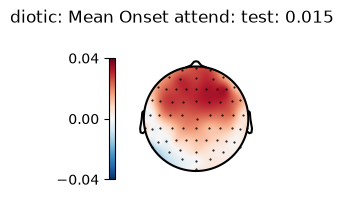

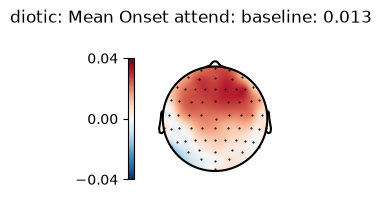

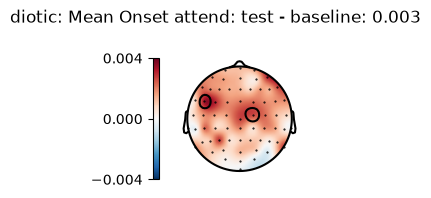

In [7]:
# Onset attend unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(ATTEND), 'diotic')
show_topomap_trio(data, diff, result, 'Onset attend', 'diotic', onset(ATTEND))

In [8]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .003>

Onset attend (diotic): ROI unique contribution t(12) = 2.603, p = 0.0115


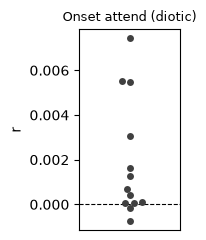

In [9]:
p = show_subject_swarm(diff, 'Onset attend', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, onset ignore unique contribution**

- Ignored onsets add predictive power: t_max = 6.70, p < 0.001
- Key finding: the ignored speaker is represented even after accounting for the mixture and the attended speaker

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

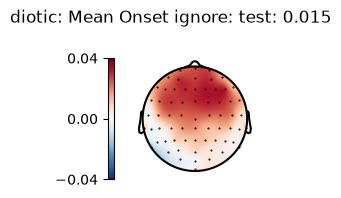

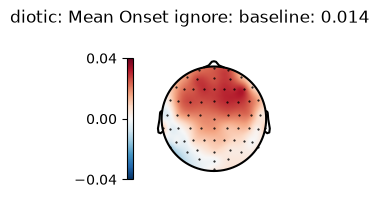

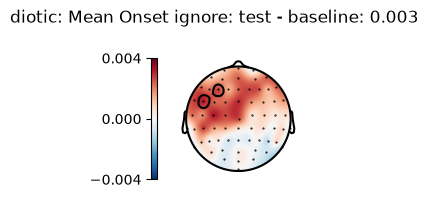

In [10]:
# Onset ignore unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(IGNORE), 'diotic')
show_topomap_trio(data, diff, result, 'Onset ignore', 'diotic', onset(IGNORE))

In [11]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .024>

Onset ignore (diotic): ROI unique contribution t(12) = 2.210, p = 0.0236


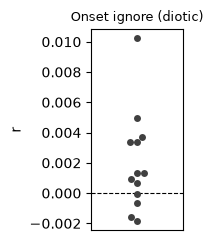

In [12]:
p = show_subject_swarm(diff, 'Onset ignore', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, onset mix unique contribution**

- Mixture onsets add predictive power: t_max = 8.61, p < 0.001

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


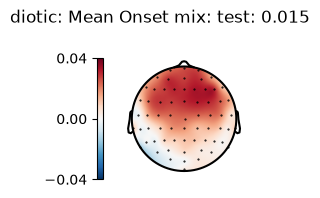

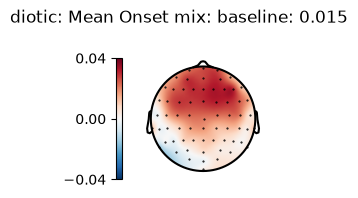

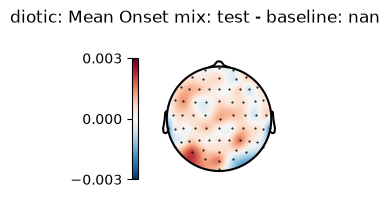

In [13]:
# Onset mix unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(MIX), 'diotic')
show_topomap_trio(data, diff, result, 'Onset mix', 'diotic', onset(MIX))

In [14]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .058>

Onset mix (diotic): ROI unique contribution t(12) = 1.741, p = 0.0536


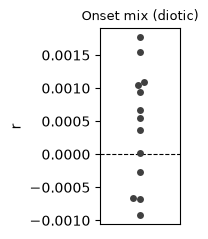

In [15]:
p = show_subject_swarm(diff, 'Onset mix', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, envelope attend unique contribution**

- Attended envelope adds predictive power: t_max = 7.37, p < 0.001

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


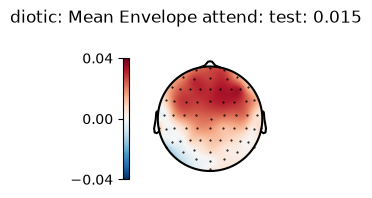

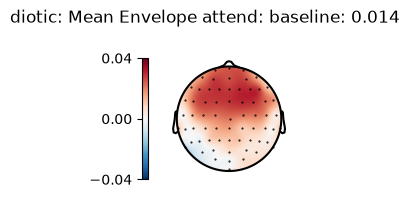

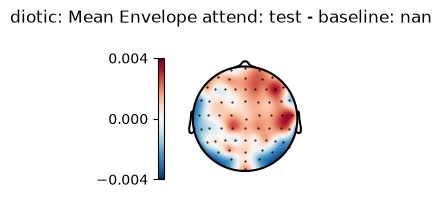

In [16]:
# Envelope attend unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(ATTEND), 'diotic')
show_topomap_trio(data, diff, result, 'Envelope attend', 'diotic', envelope(ATTEND))

In [17]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .363>

Envelope attend (diotic): ROI unique contribution t(12) = 0.570, p = 0.2896


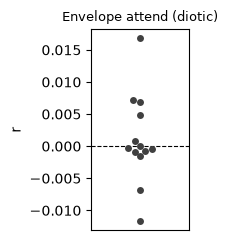

In [18]:
p = show_subject_swarm(diff, 'Envelope attend', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, envelope ignore unique contribution**

- Ignored envelope adds predictive power: t_max = 6.28, p < 0.001

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


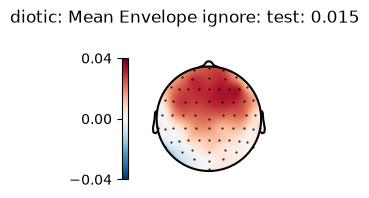

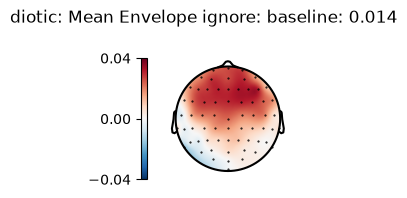

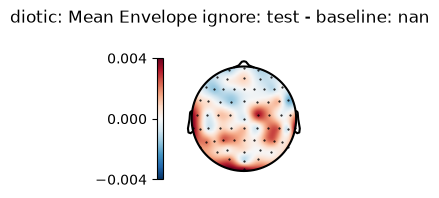

In [19]:
# Envelope ignore unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(IGNORE), 'diotic')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'diotic', envelope(IGNORE))

In [20]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .494>

Envelope ignore (diotic): ROI unique contribution t(12) = 0.024, p = 0.4904


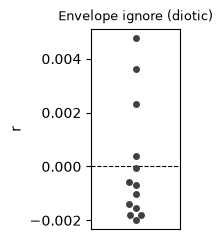

In [21]:
p = show_subject_swarm(diff, 'Envelope ignore', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, envelope mix unique contribution**

- Mixture envelope adds predictive power: t_max = 5.70, p < 0.001

</small>

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


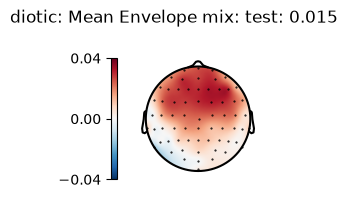

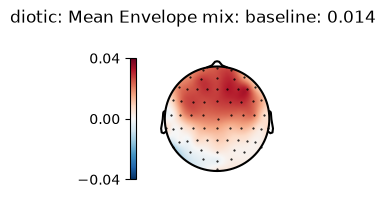

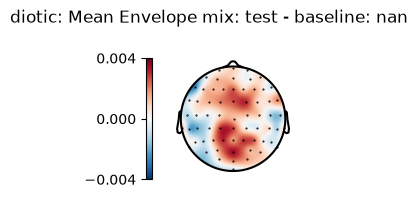

In [22]:
# Envelope mix unique contribution (diotic)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(MIX), 'diotic')
show_topomap_trio(data, diff, result, 'Envelope mix', 'diotic', envelope(MIX))

In [23]:
display(result)
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (diotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .456>

Envelope mix (diotic): ROI unique contribution t(12) = 0.554, p = 0.2950


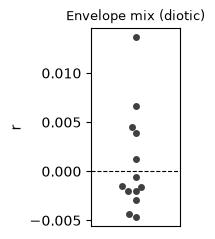

In [24]:
p = show_subject_swarm(diff, 'Envelope mix', 'diotic')

<small>

**Brodbeck et al. 2020: Two talkers, STRFs (mix, attend, ignore)**

- Onsets: same positive-then-negative shape as for clean speech
- Positive peak: earliest and biggest for the mixture
- Negative peak: only for the mixture and the attended speaker, none for the ignored speaker
- Envelope: lower amplitude, but a strong attention effect (attended > ignored)

</small>

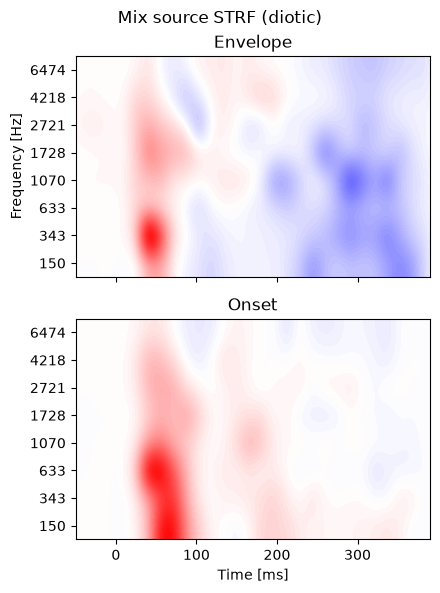

In [25]:
# Mix source STRF: envelope + onset (diotic)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

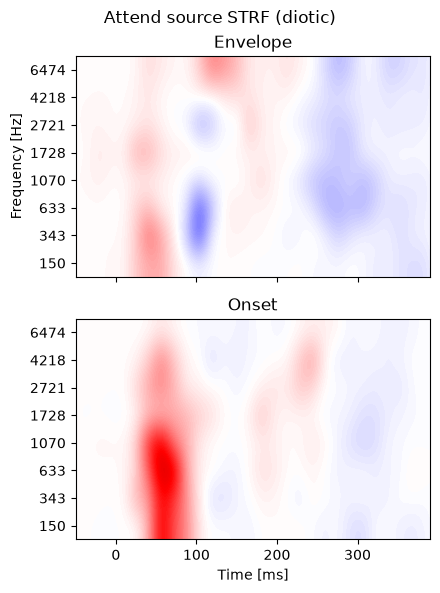

In [26]:
# Attend source STRF: envelope + onset (diotic)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

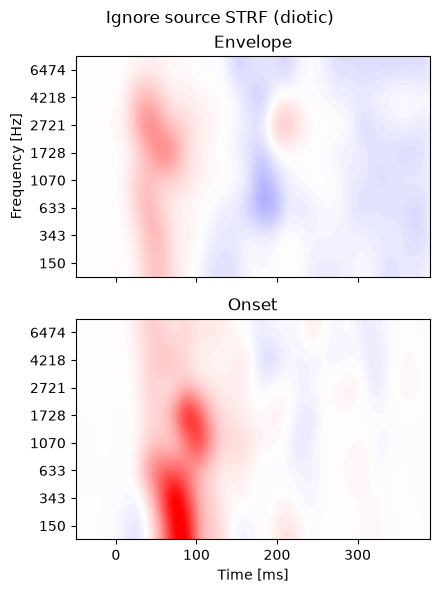

In [27]:
# Ignore source STRF: envelope + onset (diotic)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (diotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

<small>

**Brodbeck et al. 2020: Two talkers, onset peak latencies**

- Positive peak: mixture 72 ms, attended 81 ms, ignored 89 ms
- Negative peak: mixture 136 ms, attended 150 ms, ignored none
- Peak search window: 20 to 200 ms (this notebook: 40 to 200 ms)

</small>

In [28]:
# Onset attend peak amplitude & timing (diotic)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (diotic) positive peak: 61 ms, amp 0.005554
Onset attend (diotic) negative peak: 149 ms, amp -0.0007628


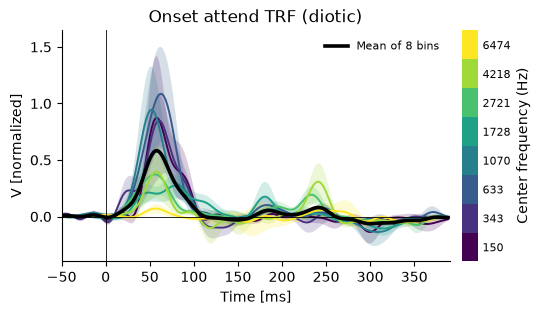

In [29]:
# Onset attend TRF per frequency bin (diotic)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (diotic)')

In [30]:
# Onset ignore peak amplitude & timing (diotic)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (diotic) positive peak: 83 ms, amp 0.004549
Onset ignore (diotic) negative peak: 184 ms, amp -0.0003915


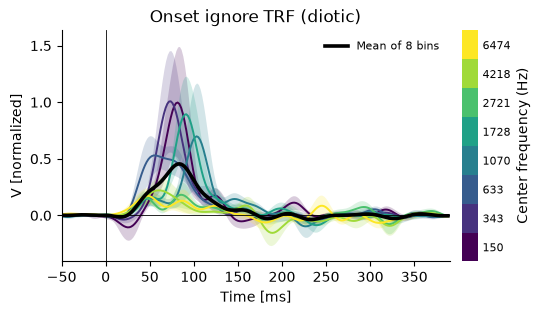

In [31]:
# Onset ignore TRF per frequency bin (diotic)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (diotic)')

In [32]:
# Onset mix peak amplitude & timing (diotic)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (diotic) positive peak: 58 ms, amp 0.004843
Onset mix (diotic) negative peak: 121 ms, amp -0.0001313


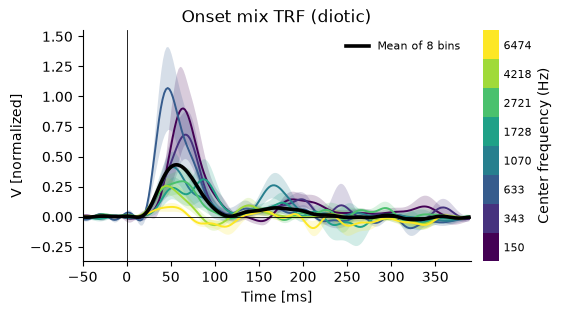

In [33]:
# Onset mix TRF per frequency bin (diotic)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (diotic)')

<small>

**Brodbeck et al. 2020: Two talkers, envelope peaks**

- No envelope peak latencies reported; only the attention effect (see the attention-effect cell below)

</small>

In [34]:
# Envelope attend peak amplitude & timing (diotic)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (diotic) positive peak: 48 ms, amp 0.00169
Envelope attend (diotic) negative peak: 106 ms, amp -0.001594


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1968: UserWarning: positive anchor (all) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


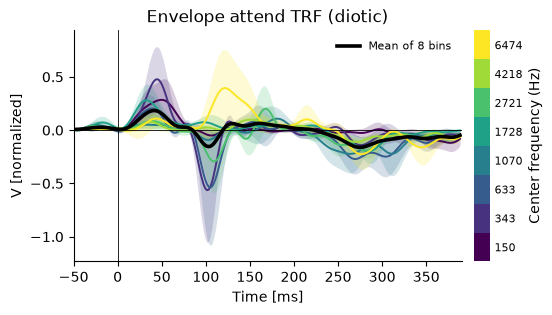

In [35]:
# Envelope attend TRF per frequency bin (diotic)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (diotic)')

In [36]:
# Envelope ignore peak amplitude & timing (diotic)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (diotic) positive peak: 47 ms, amp 0.002244
Envelope ignore (diotic) negative peak: 176 ms, amp -0.001394


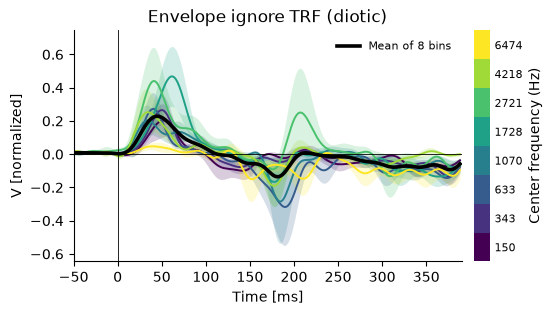

In [37]:
# Envelope ignore TRF per frequency bin (diotic)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (diotic)')

In [38]:
# Envelope mix peak amplitude & timing (diotic)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (diotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (diotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (diotic) positive peak: 49 ms, amp 0.003177
Envelope mix (diotic) negative peak: 99 ms, amp -0.0008392


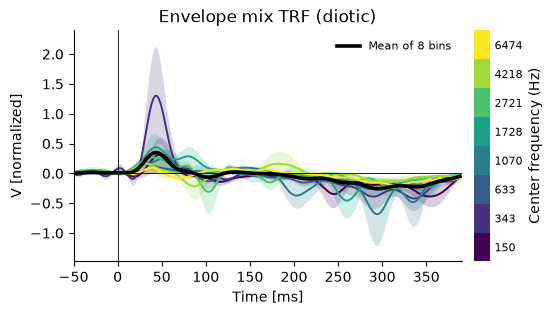

In [39]:
# Envelope mix TRF per frequency bin (diotic)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (diotic)')

<small>

**Brodbeck et al. 2020: Two talkers, onset peak comparison**

- Positive peak later for attended than mixture: 81 vs 72 ms, t(25) = 4.47, p < 0.001
- Positive peak later for ignored than mixture: 89 vs 72 ms, t(25) = 6.92, p < 0.001
- Positive peak bigger for mixture than attended: t(25) = 8.41, p < 0.001
- Positive peak bigger for mixture than ignored: t(25) = 7.66, p < 0.001
- Negative peak later for attended than mixture: 150 vs 136 ms, t(25) = 3.20, p = 0.004
- Negative peak amplitude: no difference (mixture vs attended), t(25) = 1.56, p = 0.132

</small>

In [40]:
# Onset peak comparison across mix, attend, and ignore (diotic)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

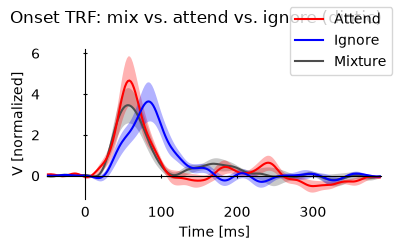

In [41]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (diotic)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [42]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 41     1.485e-05
02        mix                 46      0.002344
03        mix                 52      0.005785
04        mix                 74      0.003553
05        mix                 52      0.003166
06        mix                 41      0.005271
07        mix                 76      0.004289
08        mix                 46      0.009511
09        mix                 76      0.007336
10        mix                 60       0.01146
11        mix                 66      0.005275
12        mix                 70       0.00179
13        mix                 52      0.003161
01        attend              41     5.587e-05
02        attend              56       0.01237
03        attend              52      0.003881
04        attend              46      0.006459
05        attend              54       0.01425
06        attend              54      0.001779
07        attend              82      0.00147

In [43]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -0.89 p = .391,t12 = -3.79** p = .003
attend,,t12 = -3.71** p = .003


,attend,ignore
mix,t12 = -4.15** p = .001,t12 = -16.63*** p < .001
attend,,t12 = -5.69*** p < .001


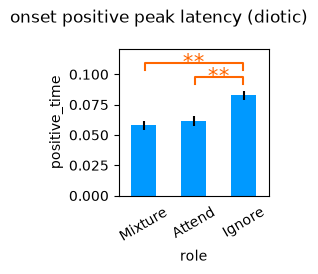

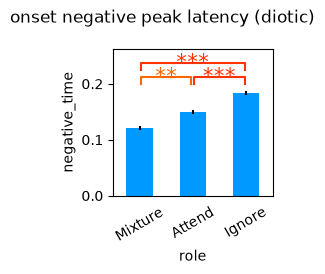

In [44]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (diotic)')
p.set_xtick_rotation(30)

In [45]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -0.53 p = .605,t12 = 0.28 p = .782
attend,,t12 = 0.81 p = .436


,attend,ignore
mix,t12 = 2.10 p = .058,t12 = 1.08 p = .301
attend,,t12 = -1.14 p = .277


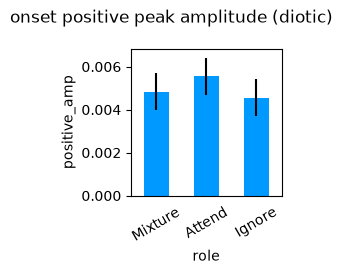

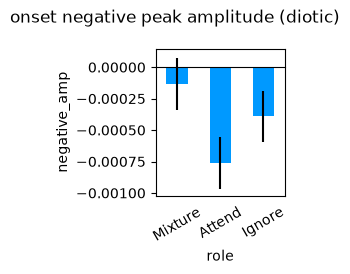

In [46]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (diotic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope peak comparison**

- No envelope peak comparison reported

</small>

In [47]:
# Envelope peak comparison across mix, attend, and ignore (diotic)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1968: UserWarning: positive anchor (attend) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


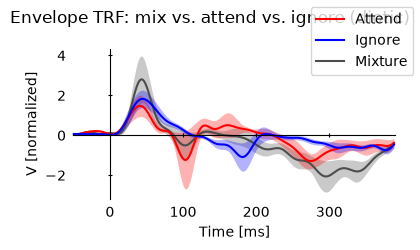

In [48]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (diotic)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [49]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 43     4.073e-05
02        mix                 48     9.505e-05
03        mix                 48     0.0006428
04        mix                 41      0.007134
05        mix                 66     0.0005542
06        mix                 43     0.0005881
07        mix                 48       0.01024
08        mix                 66      0.001195
09        mix                 58      0.001186
10        mix                 41       0.01318
11        mix                 45    -0.0008932
12        mix                 54      0.003034
13        mix                 41      0.004301
01        attend              41     6.402e-05
02        attend              41      0.001872
03        attend              45      0.001321
04        attend              41      0.003271
05        attend              50     0.0004536
06        attend              41      0.005314
07        attend              64      0.00104

In [50]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 0.31 p = .761,t12 = 0.88 p = .396
attend,,t12 = 0.31 p = .760


,attend,ignore
mix,t12 = -1.04 p = .320,t12 = -10.19*** p < .001
attend,,t12 = -10.81*** p < .001


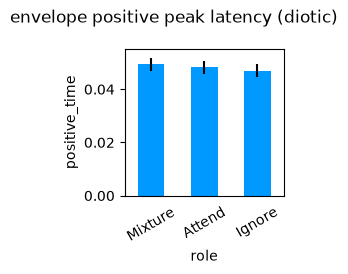

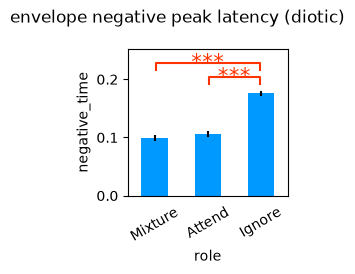

In [51]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (diotic)')
p.set_xtick_rotation(30)

In [52]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 1.39 p = .190,t12 = 0.74 p = .471
attend,,t12 = -0.76 p = .461


,attend,ignore
mix,t12 = 0.48 p = .640,t12 = 0.54 p = .600
attend,,t12 = -0.13 p = .901


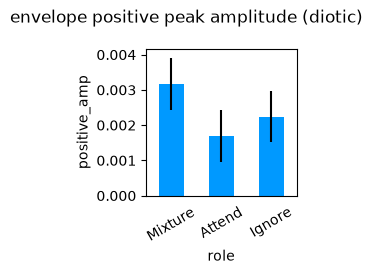

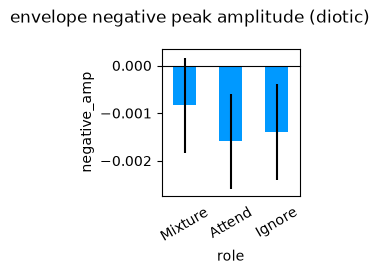

In [53]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (diotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (diotic)')
p.set_xtick_rotation(30)

<small>

**Brodbeck et al. 2020: Two talkers, envelope attention effect (attend - ignore)**

- Negative peak at about 100 ms
- Positive peak at about 200 ms
- The attention effect starts almost as early as the earliest response

</small>

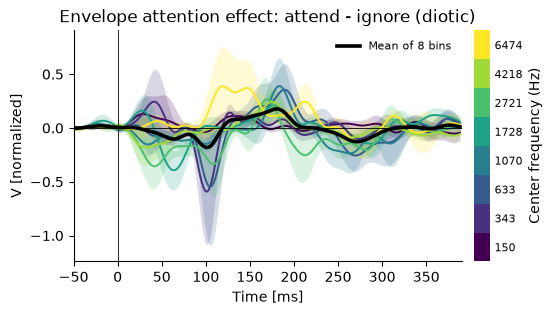

In [54]:
# Envelope attention effect: attend - ignore (diotic)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (diotic)', subtract='bg_gammatone_8')

<small>

**Brodbeck et al. 2020: Two talkers, onset attention effect (attend - ignore)**

- Early positive peak: little or no attention effect
- Later negative peak (about 136 to 150 ms): attended only, so a clear attention effect there

</small>

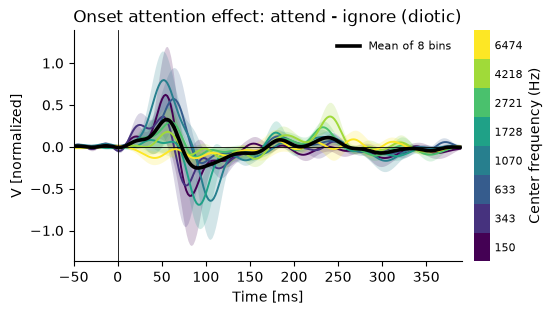

In [55]:
# Onset attention effect: attend - ignore (diotic)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (diotic)', subtract='bg_gammatone_on_8')